# The OperationsResearch2 Spring-2025 problem

## Summary

We built an optimization model to assign ships to berths while minimizing costs from waiting time and extra capacity. The model respects berth limits, unloading durations, and ship priorities. We also created visual and text-based reports from the solution for clear scheduling analysis.


## Pyomo formulation
We begin by importing the Pyomo package and creating a model abstract object:

In [ ]:
from pyomo.environ import *
infinity = float('inf')
model = AbstractModel(name='OR2 project')

### Sets

The sets $Ships$ and $Berths$ are declared abstractly using the `Set` component:

In [ ]:
model.Ships = Set()
model.Berths = Set()

### Parameters

Similarly, we add parameters, the model parameters are defined abstractly using the `Param` component:

In [ ]:
model.M = 999999999
epsilon = 1e-9
model.max_waiting_without_priority = 80

In [ ]:
model.berthNumberOfAnchs = Param(model.Berths,within=NonNegativeIntegers)
model.shipLength = Param(model.Ships, within=NonNegativeReals,default=infinity)
model.berthMaxCapacityIncrease = Param(model.Berths, within=NonNegativeReals)
model.berthLag = Param(model.Berths, within=NonNegativeReals)
model.berthCapacity = Param(model.Berths, within=NonNegativeIntegers)
model.berthLength = Param(model.Berths,within=NonNegativeReals)
model.shipArrivalTime = Param(model.Ships, within=NonNegativeReals)
model.unloadShipInAnchTime = Param(model.Ships,model.Berths,within=NonNegativeReals)
model.berthIncreaseCapCost = Param(model.Berths,within=NonNegativeReals)
model.shipCargoSize = Param(model.Ships,within= NonNegativeIntegers)
model.shipPriority= Param(model.Ships, within= NonNegativeReals)
model.shipPriorityMatrix = Param(model.Ships,model.Ships,within = Binary)
#model.shipLayoverCost = Param(model.Ships, model.Berths, within=NonNegativeReals)

### Variables

The `within` option here is used in these parameter declarations to define expected properties of the parameters.  This information is used to perform error checks on the data that is used to initialize the parameter components.

The `Var` component is used to define the decision variables:
the `binary` is `{0,1}` to be clear.

In [ ]:
model.berthCapIncrease = Var(model.Berths, within=NonNegativeIntegers)
model.shipWaitingTime = Var(model.Ships, within=NonNegativeReals)
model.shipWaitingTime_parts = Var([1,2,3],model.Ships,within=NonNegativeReals)
model.shipWaitingTime_binary_helpers = Var([1,2],model.Ships,within=Binary)
model.shipCostOfWaiting = Var(model.Ships,within=NonNegativeReals)
model.shipAssignment = Var(model.Ships,model.Berths,within=Binary)
model.shipUnloadStart = Var(model.Ships, within= NonNegativeReals)
model.shipiUnloadBeforekInBerth = Var(model.Ships,model.Ships,model.Berths,within=Binary)

### Constraints
- sequencing constraints.

In [ ]:
def sequencing_rule1(model, i, k, j):
    if i == k:
        return Constraint.Skip
    return model.shipUnloadStart[k] >= model.shipUnloadStart[i] + model.unloadShipInAnchTime[i, j] +\
           model.berthLag[j] - model.M * (1 - model.shipiUnloadBeforekInBerth[i, k, j])
model.Sequencing1 = Constraint(model.Ships, model.Ships, model.Berths, rule=sequencing_rule1)

In [ ]:
def sequencing_rule2(model, i, k, j):
    if i == k:
        return Constraint.Skip
    return model.shipUnloadStart[i] >= model.shipUnloadStart[k] + model.unloadShipInAnchTime[k, j] +\
           model.berthLag[j] - model.M * model.shipiUnloadBeforekInBerth[i, k, j]
#model.Sequencing2 = Constraint(model.Ships, model.Ships, model.Berths, rule=sequencing_rule2)

In [ ]:
def z_activation1(model, i, k, j):
    if i == k:
        return Constraint.Skip
    return model.shipiUnloadBeforekInBerth[i, k, j] <= model.shipAssignment[i, j]
model.ZActive1 = Constraint(model.Ships, model.Ships, model.Berths, rule=z_activation1)

In [ ]:
def z_activation2(model, i, k, j):
    if i == k:
        return Constraint.Skip
    return model.shipiUnloadBeforekInBerth[i, k, j] <= model.shipAssignment[k, j]
model.ZActive2 = Constraint(model.Ships, model.Ships, model.Berths, rule=z_activation2)

In [ ]:
def z_activation3(model, i, k, j):
    if i == k:
        return Constraint.Skip
    return model.shipiUnloadBeforekInBerth[i, k, j]+model.shipiUnloadBeforekInBerth[k, i, j] >=\
           model.shipAssignment[k, j] + model.shipAssignment[i, j] - 1
model.ZActive3 = Constraint(model.Ships, model.Ships, model.Berths, rule=z_activation3)

In [ ]:
def symmetry_rule(model, i, k, j):
    if i >= k:
        return Constraint.Skip
    return model.shipiUnloadBeforekInBerth[i, k, j] + model.shipiUnloadBeforekInBerth[k, i, j] <= 1
model.ZSymmetry = Constraint(model.Ships, model.Ships, model.Berths, rule=symmetry_rule)

- ordering with priority

In [ ]:
def priority_seq_rule(model, i, k, d):
    if i != k:
        return model.shipiUnloadBeforekInBerth[i, k, d] >= -2+model.shipPriorityMatrix[i, k]+model.shipAssignment[i,d]+\
                                                                                             model.shipAssignment[k,d]
    return Constraint.Skip

In [ ]:
model.PrioritySequencing = Constraint(model.Ships, model.Ships, model.Berths, rule=priority_seq_rule)

- each ship is assigned to one berth

In [ ]:
def ship_assignment_rule_top(model,i):
    return sum(model.shipAssignment[i,j] for j in model.Berths) <= 1
def ship_assignment_rule_bottom(model,i):
    return sum(model.shipAssignment[i,j] for j in model.Berths) >= 1
model.ship_assignment_limit_top = Constraint(model.Ships,rule=ship_assignment_rule_top)
model.ship_assignment_limit_bottom = Constraint(model.Ships,rule=ship_assignment_rule_bottom)

- rules for cost of waiting

In [ ]:
def cost_sum_rule_bottom(model,i):
    return model.shipCostOfWaiting[i] >= 25*model.shipWaitingTime_parts[1,i]+\
                                         10*model.shipWaitingTime_parts[2,i]+\
                                         5*model.shipWaitingTime_parts[3,i]
model.cost_sum_limit_bottom = Constraint(model.Ships,rule=cost_sum_rule_bottom)

In [ ]:
def cost_sum_rule_top(model,i):
    return model.shipCostOfWaiting[i] <= 25*model.shipWaitingTime_parts[1,i]+\
                                         10*model.shipWaitingTime_parts[2,i]+\
                                         5*model.shipWaitingTime_parts[3,i]
model.cost_sum_limit_top = Constraint(model.Ships,rule=cost_sum_rule_top)

In [ ]:
def waiting_sum_rule_bottom(model,i):
    return model.shipWaitingTime[i] >= model.shipWaitingTime_parts[1,i]+\
                                       model.shipWaitingTime_parts[2,i]+\
                                       model.shipWaitingTime_parts[3,i]
model.waiting_sum_limit_bottom = Constraint(model.Ships,rule=waiting_sum_rule_bottom)

In [ ]:
def waiting_sum_rule_top(model,i):
    return model.shipWaitingTime[i] <= model.shipWaitingTime_parts[1,i]+\
                                       model.shipWaitingTime_parts[2,i]+\
                                       model.shipWaitingTime_parts[3,i]
model.waiting_sum_limit_top = Constraint(model.Ships,rule=waiting_sum_rule_top)

In [ ]:
def cost_part1_bottom(model,i):
    return 10*model.shipWaitingTime_binary_helpers[1,i] <= model.shipWaitingTime_parts[1,i]
model.cost_part1_bottom_limit = Constraint(model.Ships,rule=cost_part1_bottom)

In [ ]:
def cost_part1_top(model,i):
    return 10 >= model.shipWaitingTime_parts[1,i]
model.cost_part1_top_limit = Constraint(model.Ships,rule=cost_part1_top)

In [ ]:
def cost_part2_bottom(model,i):
    return 30*model.shipWaitingTime_binary_helpers[2,i] <= model.shipWaitingTime_parts[2,i]
model.cost_part2_bottom_limit = Constraint(model.Ships,rule=cost_part2_bottom)

In [ ]:
def cost_part2_top(model,i):
    return 30*model.shipWaitingTime_binary_helpers[1,i] >= model.shipWaitingTime_parts[2,i]
model.cost_part2_top_limit = Constraint(model.Ships,rule=cost_part2_top)

In [ ]:
def cost_part3_top(model,i):
    return 30*model.shipWaitingTime_binary_helpers[2,i] >= model.shipWaitingTime_parts[3,i]
model.cost_part3_top_limit = Constraint(model.Ships,rule=cost_part3_top)

In [ ]:
def max_waiting_rule(model,i):
    return model.shipWaitingTime[i] <= (1-model.shipPriority[i])*model.max_waiting_without_priority
model.max_waiting_limit = Constraint(model.Ships,rule=max_waiting_rule)

- maximum increase

In [ ]:
def cap_increase_rule(model,j):
    return model.berthCapIncrease[j] <= model.berthMaxCapacityIncrease[j]
model.cap_increase_limit = Constraint(model.Berths, rule=cap_increase_rule)

- berth limit of unloaded containers

In [ ]:
def berth_unload_rule(model, j):
    return sum(model.shipAssignment[i,j]*model.shipCargoSize[i] for i in model.Ships) <= \
           model.berthCapacity[j]+model.berthCapIncrease[j]
model.berth_unload_limit = Constraint(model.Berths,rule=berth_unload_rule)

- max berth anchs

In [ ]:
def max_anch_rule(model,j):
    return sum(model.shipAssignment[i,j] for i in model.Ships) <= model.berthNumberOfAnchs[j]
model.max_anch_limit = Constraint(model.Berths, rule=max_anch_rule)

In [ ]:
def min_anch_rule(model):
    return sum(model.shipAssignment[i,'B3'] for i in model.Ships) >= model.berthNumberOfAnchs['B3']
model.min_anch_limit = Constraint(rule=min_anch_rule)

- length of ship and berth

In [ ]:
def length_of_berth_rule(model,i,j):
    return model.shipAssignment[i,j]*model.shipLength[i] <= model.berthLength[j]
model.length_of_berth_limit = Constraint(model.Ships,model.Berths,rule=length_of_berth_rule)

- Si>=Ei

In [ ]:
def unload_after_arrival_rule(model,i):
    return model.shipUnloadStart[i] >= model.shipArrivalTime[i]
model.unload_after_arrival_rule = Constraint(model.Ships, rule=unload_after_arrival_rule)
 
#8- Wi = Si-Ei

In [ ]:
def wait_time_bottom_rule(model,i):
    return model.shipWaitingTime[i] >= model.shipUnloadStart[i]-model.shipArrivalTime[i]

In [ ]:
model.wait_time_bottom_limit = Constraint(model.Ships, rule = wait_time_bottom_rule)

In [ ]:
def wait_time_top_rule(model,i):
    return model.shipWaitingTime[i] <= model.shipUnloadStart[i]-model.shipArrivalTime[i]

In [ ]:
model.wait_time_top_limit = Constraint(model.Ships, rule = wait_time_top_rule)

- The `Objective` component is used to define the cost objective. This component uses a rule function to construct the objective expression:
$sense=minimize$ means we want to minimize the cost.


In [ ]:
def cost_rule(model):
    return sum(model.berthIncreaseCapCost[j]*model.berthCapIncrease[j] for j in model.Berths)+\
           sum(model.shipCostOfWaiting[i] for i in model.Ships)+\
           5*sum(sum(model.shipAssignment[i,j]*model.unloadShipInAnchTime[i,j] for j in model.Berths)\
                for i in model.Ships)
model.cost = Objective(rule=cost_rule, sense=minimize)

## model data
since we have made an abstract model, we can add the data after creating model, to see the data we are feeding the model

execute command below or have a look at parameters.dat:

In [1]:
!cat parameters.dat

param:  Ships: shipCargoSize  shipLength shipPriority            shipArrivalTime:=
        S1      6              114        0.963796539422219       4.76552698703798
        S2      18             126        0.773138121490224       1.00459250301696
        S3      20             115        0.441550822305409       3.65299865044074
        S4      5              102        0.981939254756643       6.05417812493725
        S5      11             102        0.190926111844882       1.86918947987366
        S6      19             131        0.348681095490094       2.11799021925453
        S7      20             119        0.970486629114157       4.62295182452406
        S8      13             138        0.445607269149139       6.60117838343523 ;


param:  Berths: berthNumberOfAnchs berthCapacity berthLength berthLag           berthIncreaseCapCost berthMaxCapacityIncrease:=
        B1       2                  57            118         6.92209432152046   5.87153988992838     29
        B2      

## Solution
To get the result of a problem,you can execute the command below:
(plots are not shown using this command)

make sure to replace `-problem-number` with correct number.

Use:


    -a: to solve main problem

    -b: to solve the relaxation of Berth3 constraint

    -c: sensitivity analysis 1

    -d: sensitivity analysis 2

    -e: sensitivity analysis 3

    -f: sensitivity analysis 4

    -g: sensitivity analysis 5



In [ ]:
%matplotlib inline
%run model_runner.py -problem-number

### Problem A (main)

Execute code below to see the results:

total cost: 1803.2706014754367
Ship Berth  Arrival  Start  Wait  Duration   End
  S4    B1     6.05   6.05  0.00      9.35 15.40
  S1    B2     4.77   4.77  0.00      8.32 13.09
  S6    B2     2.12  22.81 20.70      8.09 30.90
  S7    B3     4.62   4.62  0.00      8.73 13.36
  S3    B3     3.65  22.92 19.27      8.76 31.68
  S5    B3     1.87  41.25 39.38      9.96 51.21
  S2    B4     1.00   1.00  0.00      8.09  9.09
  S8    B4     6.60  14.84  8.24      8.13 22.97


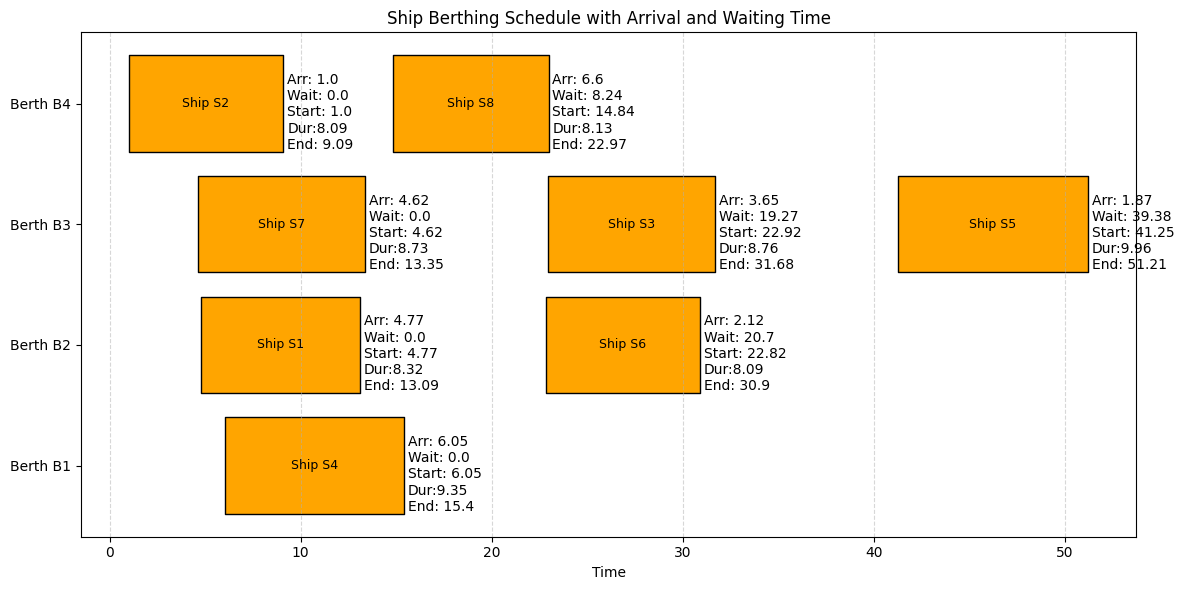

<Figure size 640x480 with 0 Axes>

In [4]:
%matplotlib inline
%run model_runner.py -a


#### Explanation

As we see, the total cost for the main problem is $$ cost=1803.271 $$

The sequencing of ships in berths is shown in both graphical and text way.

### Problem B (relaxation)

Execute code below to see the resuls:

total cost: 1605.5574639445936
Ship Berth  Arrival  Start  Wait  Duration   End
  S4    B1     6.05   6.05  0.00      9.35 15.40
  S5    B1     1.87  22.33 20.46      8.27 30.59
  S1    B2     4.77   4.77  0.00      8.32 13.09
  S6    B2     2.12  22.81 20.70      8.09 30.90
  S7    B3     4.62   4.62  0.00      8.73 13.36
  S3    B3     3.65  22.92 19.27      8.76 31.68
  S2    B4     1.00   1.00  0.00      8.09  9.09
  S8    B4     6.60  14.84  8.24      8.13 22.97


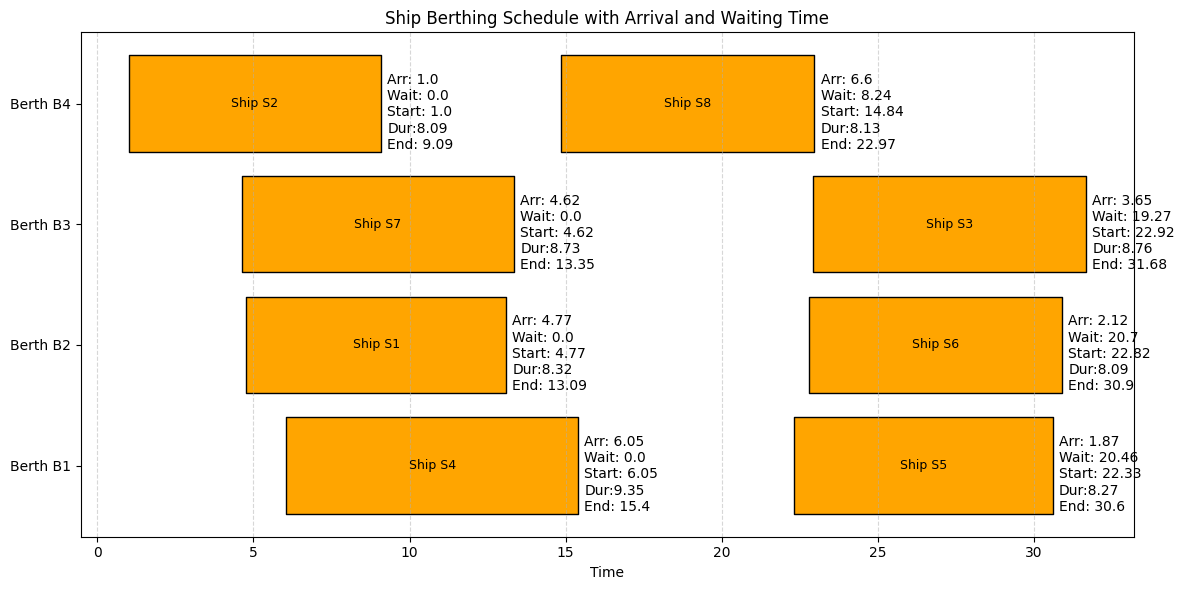

<Figure size 640x480 with 0 Axes>

In [5]:
%matplotlib inline
%run model_runner.py -b


#### Explanation

As we expected, when we relax the berth3 lower limit, because the feasible space gets bigger, the answer could be lower, and it is lower: 

$$cost = 1605.557 $$

### Problem C (sensitivity analysis 1)

Execute code below to see the resuls:



Lag B2 = 5.0, Objective = 1755.9923486353946
Lag B2 = 5.5, Objective = 1760.9923486353946
Lag B2 = 6.0, Objective = 1765.9923486353946
Lag B2 = 6.5, Objective = 1770.9923486353946
Lag B2 = 7.0, Objective = 1775.9923486353946
Lag B2 = 7.5, Objective = 1780.9923486353946
Lag B2 = 8.0, Objective = 1785.9923486353946
Lag B2 = 8.5, Objective = 1790.9923486353946
Lag B2 = 9.0, Objective = 1795.9923486353946
Lag B2 = 9.5, Objective = 1800.9923486353946
Lag B2 = 10.0, Objective = 1805.9923486353946


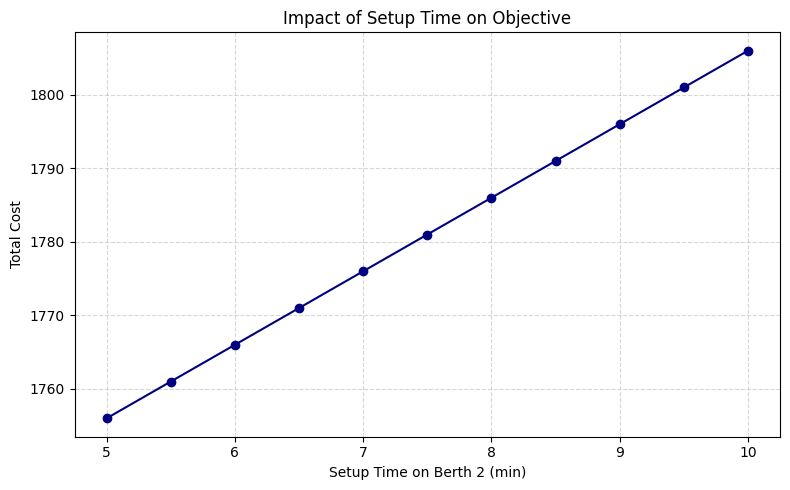

<Figure size 640x480 with 0 Axes>

In [1]:
%matplotlib inline
%run model_runner.py -c


### Problem D (sensitivity analysis 2)

Execute code below to see the resuls:



Unload Time Ship 7 @ B3 = 5.0, Objective = 1709.9633210280635
Unload Time Ship 7 @ B3 = 5.5, Objective = 1722.4633210280635
Unload Time Ship 7 @ B3 = 6.0, Objective = 1734.9633210280635
Unload Time Ship 7 @ B3 = 6.5, Objective = 1747.4633210280635
Unload Time Ship 7 @ B3 = 7.0, Objective = 1759.9633210280635
Unload Time Ship 7 @ B3 = 7.5, Objective = 1772.4633210280635
Unload Time Ship 7 @ B3 = 8.0, Objective = 1784.9633210280635
Unload Time Ship 7 @ B3 = 8.5, Objective = 1797.4633210280635
Unload Time Ship 7 @ B3 = 9.0, Objective = 1809.9633210280635
Unload Time Ship 7 @ B3 = 9.5, Objective = 1816.7014710251874
Unload Time Ship 7 @ B3 = 10.0, Objective = 1816.7014710251874
Unload Time Ship 7 @ B3 = 10.5, Objective = 1816.7014710251874
Unload Time Ship 7 @ B3 = 11.0, Objective = 1816.7014710251874
Unload Time Ship 7 @ B3 = 11.5, Objective = 1816.7014710251874
Unload Time Ship 7 @ B3 = 12.0, Objective = 1816.7014710251874
Unload Time Ship 7 @ B3 = 12.5, Objective = 1816.7014710251874
Un

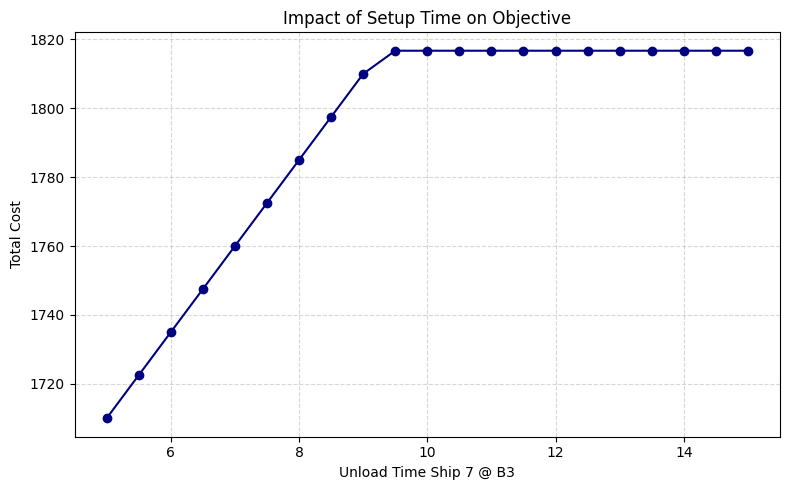

<Figure size 640x480 with 0 Axes>

In [3]:
%matplotlib inline
%run model_runner.py -d


### Problem G (sensitivity analysis 5)

Execute code below to see the resuls:



Arrival Time Ship 6 = 1.0, Objective = 1814.4505036679816
Arrival Time Ship 6 = 1.1, Objective = 1813.4505036679816
Arrival Time Ship 6 = 1.2, Objective = 1812.4505036679816
Arrival Time Ship 6 = 1.3, Objective = 1811.4505036679816
Arrival Time Ship 6 = 1.4, Objective = 1810.4505036679816
Arrival Time Ship 6 = 1.5, Objective = 1809.4505036679816
Arrival Time Ship 6 = 1.6, Objective = 1808.4505036679816
Arrival Time Ship 6 = 1.7, Objective = 1807.4505036679816
Arrival Time Ship 6 = 1.8, Objective = 1806.4505036679816
Arrival Time Ship 6 = 1.9, Objective = 1805.4505036679816
Arrival Time Ship 6 = 2.0, Objective = 1804.4505036679816
Arrival Time Ship 6 = 2.1, Objective = 1803.4505036679816
Arrival Time Ship 6 = 2.2, Objective = 1802.4505036679816
Arrival Time Ship 6 = 2.3, Objective = 1801.4505036679816
Arrival Time Ship 6 = 2.4, Objective = 1800.4505036679816
Arrival Time Ship 6 = 2.5, Objective = 1799.4505036679816
Arrival Time Ship 6 = 2.6, Objective = 1798.4505036679816
Arrival Time S

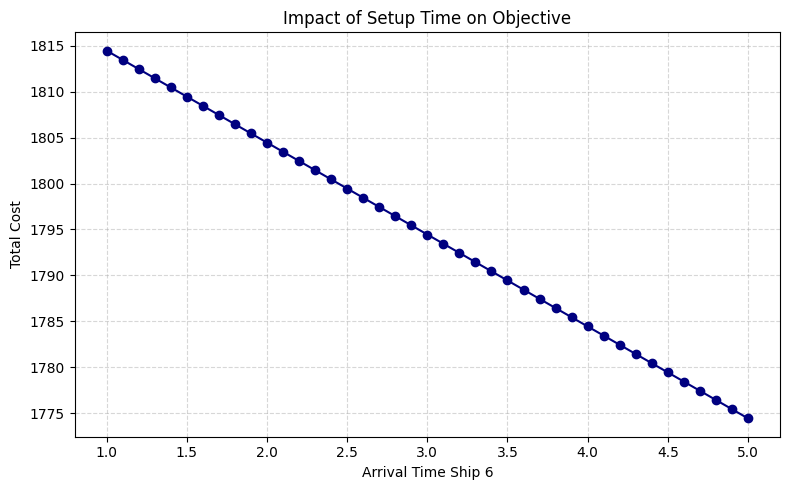

<Figure size 640x480 with 0 Axes>

In [2]:
%matplotlib inline
%run model_runner.py -g